# Análise de ranking: top 5%

Esta análise lê métricas já registradas no `mlflow.db` local. Não treina nem reavalia os modelos. Os runs analisados são `BernoulliNB_original` (`253bde4ddf134e2e820aa0d9127cb947`) e `XGBoost_over` (`bc25bb01677e4577acaa937d6fe9431f`).

## Como ler as métricas

O top 5% contém as reclamações com maior probabilidade prevista de `late_response = 1`. **Precision@5%** é a fração de positivos nesse grupo; **Recall@5%** é a fração de todos os positivos encontrada no grupo; **Lift@5%** é Precision@5% dividida pela taxa positiva do conjunto. Quando 5% do total não é inteiro, a quantidade de linhas é arredondada para cima. A Average Precision (AP) usa todo o ranking.

In [1]:
from pathlib import Path
import sqlite3

import pandas as pd
from IPython.display import display

root = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'mlflow.db').is_file()), None)
if root is None:
    raise FileNotFoundError('mlflow.db não encontrado na pasta atual ou em suas pastas superiores.')

cases = (
    ('BernoulliNB_original', 'Teste', 'test', '253bde4ddf134e2e820aa0d9127cb947'),
    ('XGBoost_over', 'Teste', 'test', 'bc25bb01677e4577acaa937d6fe9431f'),
    ('BernoulliNB_original', 'OOT', 'oot', '253bde4ddf134e2e820aa0d9127cb947'),
)
metric_names = (
    ('average_precision', 'Average Precision'),
    ('positive_rate', 'Taxa positiva'),
    ('precision_at_5_percent', 'Precision@5%'),
    ('recall_at_5_percent', 'Recall@5%'),
    ('lift_at_5_percent', 'Lift@5%'),
)

rows = []
with sqlite3.connect(root / 'mlflow.db') as connection:
    for model, split_label, split, run_id in cases:
        row = {'Modelo': model, 'Conjunto': split_label}
        for metric_key, column in metric_names:
            key = f'{split}_{metric_key}'
            result = connection.execute(
                'SELECT value FROM latest_metrics WHERE run_uuid = ? AND key = ?',
                (run_id, key),
            ).fetchone()
            if result is None:
                raise ValueError(f'Métrica ausente no run {run_id}: {key}')
            row[column] = result[0]
        rows.append(row)

ranking = pd.DataFrame(rows)
display(ranking.round(4))

,Modelo,Conjunto,Average Precision,Taxa positiva,Precision@5%,Recall@5%,Lift@5%
0,BernoulliNB_original,Teste,0.3832,0.0280,0.2886,0.5158,10.3165
1,XGBoost_over,Teste,0.2432,0.0280,0.2138,0.3823,7.6454
2,BernoulliNB_original,OOT,0.2685,0.0285,0.2356,0.4137,8.2729


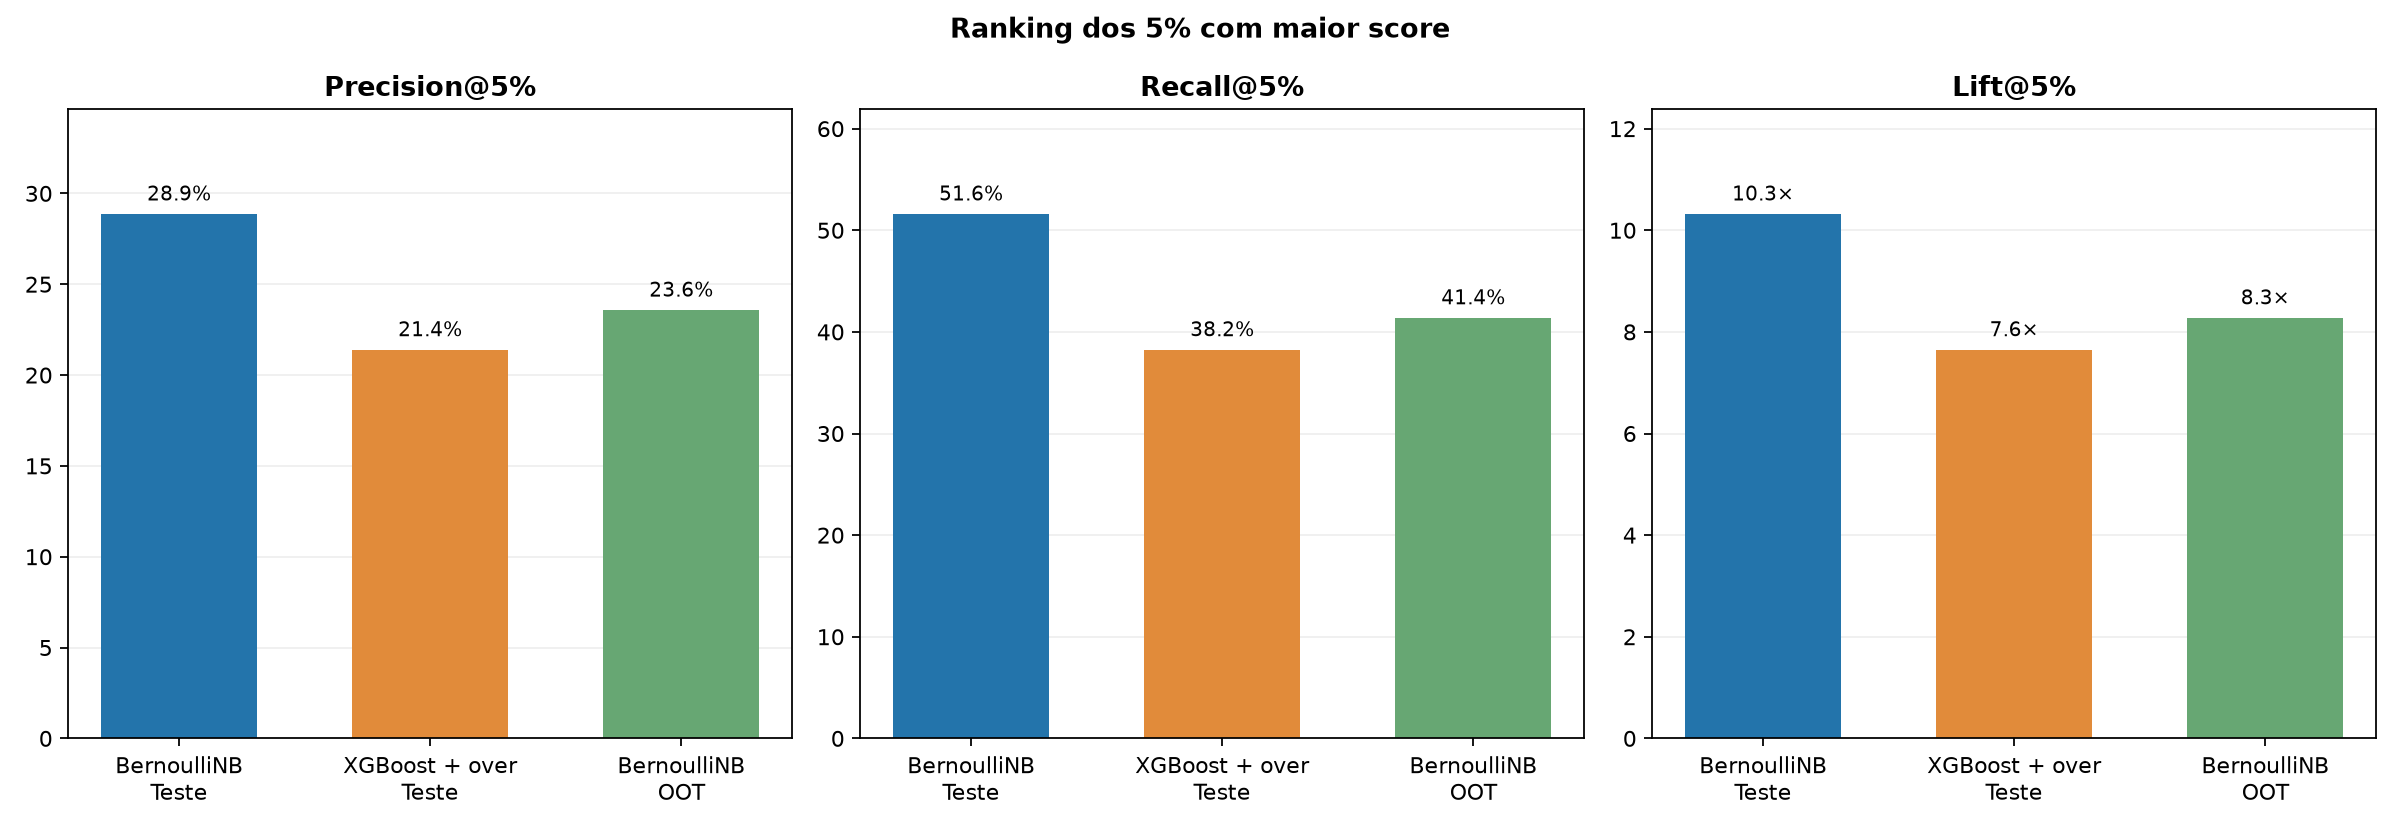

In [2]:
from IPython.display import Image

figure = root / 'reports' / 'figures' / 'test_oot_ranking_at_5_percent.png'
if not figure.is_file():
    raise FileNotFoundError('Execute src/evaluation/plot_results.py para gerar o gráfico.')
display(Image(filename=str(figure)))

## Leitura dos resultados registrados

No Teste, o BernoulliNB alcançou Precision@5% de **28,86%**, Recall@5% de **51,58%** e Lift@5% de **10,32×**. O XGBoost alcançou **21,38%**, **38,23%** e **7,65×**, respectivamente. Assim, o BernoulliNB concentrou mais casos positivos no top 5% desse conjunto.

No OOT, o BernoulliNB alcançou Precision@5% de **23,56%**, Recall@5% de **41,37%** e Lift@5% de **8,27×**. A queda em relação ao Teste indica desempenho inferior no período mais recente; a comparação não identifica a causa. O XGBoost não foi avaliado no OOT.

As métricas `precision`, `recall` e `f1` sem `@5%` usam o limiar de classificação `0,5`; elas respondem a uma pergunta diferente das métricas do top 5%. O snapshot histórico também não comprova a disponibilidade de todas as variáveis no instante da reclamação.